# Clasificador temprana/tardía: imagen sola vs. imagen + `.fits`, en las variantes finalistas

¿El `.fits` aporta algo al clasificador que no esté ya en el `.jpg` del visor? Continuación de
`notebook/variant-classification-for-images-only.ipynb`, con **el mismo método y las mismas
métricas** para que los números se puedan comparar directamente. Ver `README.md`, sección
"Imágenes + .fits: ¿aporta el .fits al clasificador?".

La pregunta se responde **en cada variante por separado**: el `.jpg` de una variante se compara con el
`.fits` de la **misma** capa y bandas, para que la única diferencia entre ambos sea el formato. Las
variantes (`FUSION_VARIANTS`) son las cuatro finalistas de la libreta de solo imágenes y, como
referencia, la variante con la que se hizo la primera versión de esta comparación:

| Variante | Por qué está |
|---|---|
| `ls-dr9_grz` | finalista |
| `ls-dr10-grz_grz` | finalista (su `.fits` es idéntico byte a byte al de `ls-dr10_grz`: la capa solo cambia el color del `.jpg`) |
| `ls-dr11_grz` | finalista |
| `ls-dr11_griz` | finalista; el `.fits` trae 4 bandas (g, r, i, z) |
| `ls-dr10_grz` | variante activa del proyecto; no pasa el filtro 1 (sur morado), se deja para comparar con la primera corrida |

En cada variante se comparan 6 representaciones de las **mismas 50 galaxias** (25 tempranas / 25
tardías):

| Representación | Qué entra al clasificador |
|---|---|
| `imagen` | 512 features de la ResNet-34 congelada sobre el `.jpg` (referencia de esa variante; es la fila "original" de la libreta de solo imágenes) |
| `fits` | 512 features de la **misma** ResNet-34 sobre el cubo `.fits` normalizado (cielo restado, asinh de Lupton, escala global; ver `README.md`, sección "Normalización de los .fits") |
| `fotometria` | 3 números medidos en el `.fits`: colores g − r, r − z y concentración en r |
| `imagen + fits` | la "red combinada": dos ramas congeladas, una por formato, con sus features concatenadas |
| `imagen + fotometria` | imagen + los 3 números de fotometría |
| `imagen + fits + fotometria` | las tres entradas juntas |

**Cómo se combina.** Cada entrada pasa por su propia rama (la ResNet para `.jpg` y `.fits`, nada para
la fotometría), los vectores se concatenan y una regresión logística clasifica (*fusión tardía*). La
regresión iguala el peso de cada bloque (`block_weights`), así 3 números de fotometría no quedan
ahogados por 512 features. Con 50 galaxias no se puede entrenar una red de dos ramas de punta a punta
sin memorizar la muestra; con las ramas congeladas, la única diferencia entre corridas es la entrada.

**Cuatro bandas con una red de tres canales.** La ResNet de ImageNet recibe 3 canales (R, G, B). Con
`grz` se usa el mapeo del visor (R = z, G = r, B = g). Con `griz`, las dos bandas más rojas (i y z)
se promedian en el canal R (`FUSION_FITS_RGB_CHANNELS`), así entran las 4 bandas sin cambiar la red.

Lógica en `src/`: `src/models/fusion_probe.py`, `src/models/linear_probe.py`,
`src/data/fits_normalization.py`, `src/data/fits_photometry.py` y `src/evaluate.py`. Las
definiciones formales y fórmulas de AUC, p-valor, IC bootstrap, F1 macro, accuracy y comparación
pareada están en la libreta de solo imágenes (secciones 1.2, 2 y 2.1).

> **Muestra chica:** con 50 galaxias solo se detectan diferencias grandes. Para la decisión real,
> descargar más `.fits` (`python -m src.data.download_cutouts --n 2000 --format fits --variants ...`)
> y volver a ejecutar esta libreta sin cambios.

### Respuesta corta

**En las cinco variantes, con estas 50 galaxias, darle a la computadora el `.fits` además de la imagen
no mejora la clasificación temprana/tardía.**

- La imagen sola es la mejor representación **en todas las variantes**: AUC 0.963–0.979 y 44–46
  aciertos de 50.
- Las combinaciones con `.fits` o fotometría **nunca la superan**: empatan, y en `ls-dr11_griz` la
  combinación `imagen + fits` es incluso significativamente peor.
- El `.fits` solo es **significativamente peor en las cinco variantes** (AUC 0.83–0.88), sobre todo con
  las galaxias del sur.
- Tres números de fotometría clásica (dos colores y la concentración) casi igualan a la imagen
  (AUC 0.94) en todas las variantes.

La conclusión de la primera corrida (solo `ls-dr10_grz`) **no dependía de la variante**. El detalle y
las salvedades están en "Observaciones y conclusiones", al final de la libreta.

### Guía de lectura para no especialistas en IA

**La pregunta.** Un astrónomo clasifica bien una galaxia mirando la imagen en color del visor (el
`.jpg`). La computadora, ¿clasificaría mejor si además recibiera el dato calibrado (el `.fits`) o
medidas fotométricas? Si no gana nada, conviene seguir con el `.jpg`, que es ~35 veces más ligero y
no necesita procesamiento propio. Como la libreta de solo imágenes dejó varias variantes empatadas,
la pregunta se repite en cada una: la respuesta podría depender de la variante.

**Cómo "mira" la computadora.** Usamos una red neuronal (ResNet-34) ya entrenada con millones de
fotos cotidianas (perros, coches, paisajes). La red está **congelada**: no se modifica. Funciona como
un instrumento fijo que convierte cada imagen en una "huella" de 512 números que resumen formas,
texturas y colores. Después, una fórmula sencilla (**regresión logística**) aprende a trazar una
frontera entre las huellas de las tempranas y las de las tardías, parecido a separar dos poblaciones
en un diagrama color–concentración, pero en 512 dimensiones.

**Qué recibe cada versión:**

- **`imagen`:** la huella del `.jpg` del visor.
- **`fits`:** la huella del `.fits`, calculada con **la misma red**. Antes hay que prepararlo para que
  se parezca a lo que la red espera de una foto: restar el cielo, comprimir el rango de brillo con un
  estiramiento asinh (el núcleo es ~100 veces más brillante que el disco) y llevar los valores a una
  escala común.
- **`fotometria`:** tres números medidos de la manera clásica: g − r, r − z y la concentración de la
  luz.
- **Combinaciones (la "red combinada"):** las huellas se ponen lado a lado y la fórmula final decide
  usando todo a la vez. Cada fuente recibe el mismo peso: los 3 números de fotometría cuentan tanto
  como los 512 de una imagen.

**Por qué no se entrena la red.** Con 50 galaxias, ajustar los millones de parámetros de una red
equivaldría a ajustar un polinomio de grado 50 a 50 puntos: pasaría por todos y no predeciría nada
nuevo (*sobreajuste* o memorización). Con la red congelada solo se ajusta la fórmula final, que tiene
pocos parámetros, y además se le impide dar demasiada importancia a cualquier detalle aislado
(*regularización*). Como el instrumento es el mismo para todos, cualquier diferencia de resultado se
debe a la entrada.

**Cómo se califica:**

- **Evaluación honesta.** Cada galaxia se clasifica con un modelo que **no la vio** al aprender, como
  reservar una submuestra de control.
- **AUC** (de 0.5 a 1): probabilidad de que, dada una tardía y una temprana al azar, el modelo indique
  correctamente cuál es la tardía. **0.5 = lanzar una moneda; 1 = siempre acierta el orden.** Como
  guía: 0.7 es una señal débil, 0.9 es buena y 0.95 o más es muy buena.
- **Accuracy:** fracción de galaxias bien clasificadas (0.92 = 46 de 50).

**Cómo leer las tablas.** Casi todas tienen una fila por (variante, representación). Para responder la
pregunta, compare **dentro de cada variante** la fila `imagen` con las filas que añaden `.fits` o
fotometría. Comparar entre variantes (p. ej. DR9 contra DR11) ya lo hizo la libreta de solo imágenes.

**Cautela.** Con 50 galaxias (25 + 25) solo se detectan diferencias grandes: sirve para descartar
opciones claramente peores, no para distinguir entre opciones casi iguales.

In [1]:
# importaciones de sistema
import sys
import warnings
from pathlib import Path

# Referencia a otros archivos sin necesidad de instalar el paquete
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# importaciones de librerias de terceros
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score

warnings.filterwarnings("ignore", category=UserWarning)  # avisos de sklearn/torch en paralelo

In [2]:
# configuracion de proyecto
from src.config import (
    CUTOUT_FORMAT_FITS,
    CUTOUTS_INDEX_CSV,
    EARLY_TYPE_LABEL,
    FUSION_PHOTOMETRY_FEATURES,
    FUSION_REFERENCE,
    FUSION_REPRESENTATIONS,
    FUSION_VARIANTS,
    LATE_TYPE_LABEL,
    LEGACY_REGION_NORTH,
    LEGACY_REGION_SOUTH,
    MORFOLOGIA_LABEL_TO_INT,
)
from src.data.cutout_io import load_jpg_cutout
from src.data.fits_normalization import normalize_fits_cube
from src.data.fits_photometry import build_fits_photometry_table
from src.data.image_quality import legacy_region
from src.data.legacy_cutouts import variant_name
from src.evaluate import (
    bootstrap_auc_ci,
    cross_group_auc,
    out_of_fold_proba,
    paired_bootstrap_auc_diff,
    predictability_test,
)
from src.models.fusion_probe import (
    embed_fits_cubes,
    fit_fits_input_stats,
    fits_out_of_fold_proba_foldwise,
    fits_rgb_channels,
    load_fits_sample,
    make_fusion_probe,
)
from src.models.linear_probe import build_backbone, embed_cutouts
from src.utils import set_seed

set_seed()

# Colores fijos (paleta categórica validada, slots 1 y 2).
CLASS_COLORS = {EARLY_TYPE_LABEL: "#eb6834", LATE_TYPE_LABEL: "#2a78d6"}
INPUT_COLORS = {"con imagen": "#2a78d6", "sin imagen": "#eb6834"}

index = pd.read_csv(CUTOUTS_INDEX_CSV)
variants = {variant_name(layer, bands): (layer, bands) for layer, bands in FUSION_VARIANTS}
representations = list(FUSION_REPRESENTATIONS)


def fits_galaxies(layer, bands):
    # Galaxias con .fits descargado en una variante, en orden de nombre.
    rows = index[(index["format"] == CUTOUT_FORMAT_FITS) & index["status"].isin(["downloaded", "cached"])
                 & (index["layer"] == layer) & (index["bands"] == bands)]
    return rows.sort_values("name").reset_index(drop=True)


# Las mismas galaxias en todas las variantes (muestra balanceada con la misma semilla).
galaxies = fits_galaxies(*FUSION_VARIANTS[0])
names = galaxies["name"].tolist()
for layer, bands in FUSION_VARIANTS[1:]:
    assert fits_galaxies(layer, bands)["name"].tolist() == names, (layer, bands)
y = galaxies["label"].map(MORFOLOGIA_LABEL_TO_INT).to_numpy()
regions = legacy_region(galaxies["objra"], galaxies["objdec"])

# Bloques de features por variante: cada uno se calcula una sola vez.
backbone = build_backbone()
raws, fits_stats, photometry, blocks = {}, {}, {}, {}
for variant, (layer, bands) in variants.items():
    raws[variant] = load_fits_sample(names, galaxies["PETRO_TH90"], layer, bands)
    fits_stats[variant] = fit_fits_input_stats(raws[variant])  # sin etiquetas; control por fold en la sección 4
    photometry[variant] = build_fits_photometry_table(galaxies[["name", "PETRO_TH90", "label"]], layer, bands)
    blocks[variant] = {
        "imagen": embed_cutouts(names, layer, bands, backbone),
        "fits": embed_fits_cubes(raws[variant], backbone, fits_stats[variant], bands),
        "fotometria": photometry[variant][list(FUSION_PHOTOMETRY_FEATURES)].to_numpy(),
    }


def representation_matrix(variant, representation):
    # Concatena los bloques de una representación y devuelve (X, tamaños de bloque).
    parts = [blocks[variant][block] for block in FUSION_REPRESENTATIONS[representation]]
    return np.hstack(parts), [part.shape[1] for part in parts]


print(f"{len(names)} galaxias ({(y == 0).sum()} tempranas / {(y == 1).sum()} tardías), "
      f"{(regions == LEGACY_REGION_NORTH).sum()} norte / {(regions == LEGACY_REGION_SOUTH).sum()} sur, "
      f"{len(variants)} variantes: {', '.join(variants)}")
display(pd.Series({name: block.shape[1] for name, block in blocks[next(iter(variants))].items()},
                  name="columnas").to_frame().T)

50 galaxias (25 tempranas / 25 tardías), 23 norte / 27 sur, 5 variantes: ls-dr9_grz, ls-dr10-grz_grz, ls-dr11_grz, ls-dr11_griz, ls-dr10_grz


,imagen,fits,fotometria
columnas,512,512,3


## 1. Qué recibe cada rama

### 1.1 `.jpg` contra `.fits` normalizado

Para dos tempranas y dos tardías: en cada renglón una variante, a la izquierda de cada par el `.jpg` del
visor y a la derecha el cubo `.fits` después de la normalización, con las bandas agrupadas en R, G, B
igual que como las recibe la red (`FUSION_FITS_RGB_CHANNELS`), mostrado hasta el flujo de referencia.
El `.fits` conserva el brillo relativo entre galaxias (escala global) y no tiene compresión JPEG; el
`.jpg` es el render del visor.

**Términos de esta sección**

- **Rama:** el camino que sigue una entrada hasta convertirse en números para la fórmula final. Hay
  una rama para el `.jpg`, otra para el `.fits` (ambas usan la misma red congelada) y otra para la
  fotometría (que no pasa por la red).
- **Normalizar el `.fits`:** transformar el flujo calibrado (nanomaggies) en valores de un rango
  parecido al de una foto, como hace el visor al generar el `.jpg`, pero con nuestras reglas: cielo
  restado, asinh de Lupton que conserva el color y una escala común a todas las galaxias.
- **Variante:** combinación de capa del survey (`ls-dr9`, `ls-dr10`, `ls-dr11`…) y bandas (`grz`,
  `griz`). Cambia el procesamiento de los datos y, en el `.jpg`, cómo el visor los colorea.

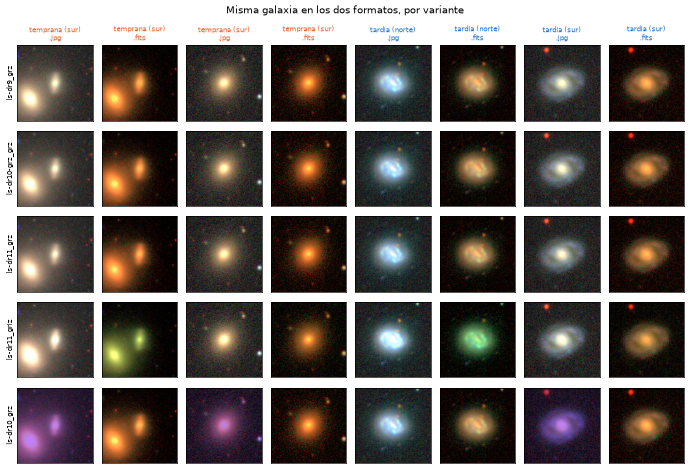

In [3]:
examples = (galaxies.assign(region=regions).groupby("label", group_keys=False).head(2)
            .sort_values("label", key=lambda s: s.map(MORFOLOGIA_LABEL_TO_INT)))
fig, axes = plt.subplots(len(variants), 2 * len(examples), figsize=(1.45 * 2 * len(examples), 1.6 * len(variants)),
                         dpi=60)
for r, (variant, (layer, bands)) in enumerate(variants.items()):
    for c, (i, row) in enumerate(examples.iterrows()):
        cube = np.nan_to_num(normalize_fits_cube(*raws[variant][i], reference=fits_stats[variant].reference))
        # Se muestra hasta el flujo de referencia (1); la red recibe el rango completo.
        fits_rgb = np.clip(fits_rgb_channels(cube, bands), 0, 1)
        panels = (load_jpg_cutout(row["name"], layer, bands), np.moveaxis(fits_rgb, 0, -1))
        for k, (image, source) in enumerate(zip(panels, (".jpg", ".fits"))):
            ax = axes[r, 2 * c + k]
            ax.imshow(image)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(f"{row['label']} ({row['region']})\n{source}", fontsize=8,
                             color=CLASS_COLORS[row["label"]])
            if c == 0 and k == 0:
                ax.set_ylabel(variant, fontsize=8)
fig.suptitle("Misma galaxia en los dos formatos, por variante")
plt.tight_layout()
plt.show()

**Lectura de la figura (para no especialistas).** Cada renglón es una variante y cada par de columnas
una galaxia: a la izquierda el `.jpg` del visor y a la derecha el `.fits` tal como lo recibe la red.
El título dice la clase y la región (norte = BASS/MzLS en Kitt Peak; sur = DECam en Chile).

- **Los `.jpg` de las cuatro finalistas se ven casi iguales** entre sí y con el mismo color en el
  norte y en el sur.
- **El `.jpg` de `ls-dr10_grz` (último renglón) pinta de morado las galaxias del sur.** Es el defecto
  del visor que hizo fallar a esta variante en el control de calidad de la libreta de solo imágenes.
  Su `.fits` no lo tiene: el morado no está en el dato.
- **Los `.fits` grz (DR9, DR10, DR11) son casi idénticos** entre sí. El de `ls-dr10-grz_grz` es
  literalmente el mismo archivo que el de `ls-dr10_grz`.
- **El `.fits` de `ls-dr11_griz` se ve verdoso o amarillento en algunas galaxias**, por ejemplo la
  tardía del norte. En DR11 la banda *i* **no existe en el norte**: el archivo trae ceros en esa
  banda en las 23 galaxias del norte, y también en 2 del sur, con otras 2 cubiertas solo en parte.
  Como *i* y *z* se promedian en el canal rojo, donde falta *i* el rojo baja a la mitad.

**Conclusión:** el `.fits` es un dato más "limpio" que el `.jpg`, pero tiene sus propias trampas. En
`ls-dr11_griz` el contenido de una banda depende del telescopio, y eso aparecerá en las secciones 2 y
3.

### 1.2 Fotometría por clase

Los 3 números del bloque `fotometria` (`src/data/fits_photometry.py`, `galaxy_photometry`): colores
g − r y r − z de apertura (1.5 × PETRO_TH90) y concentración `C = 5 log10(r80 / r20)` en la banda r.
Se excluyen magnitudes y radios en arcsec porque dependen de la distancia y la masa, no solo de la
morfología. La banda i de `ls-dr11_griz` no entra en estas medidas, así que su fotometría es la de
`ls-dr11_grz`.

In [4]:
photometry_by_class = pd.concat(
    {variant: table.groupby("label")[list(FUSION_PHOTOMETRY_FEATURES)].mean() for variant, table in photometry.items()},
    names=["variante"],
)
display(photometry_by_class.unstack("label").round(3))

g_r             r_z          concentracion         
label           tardia temprana tardia temprana        tardia temprana
variante                                                              
ls-dr9_grz       0.674    0.908  0.447    0.565         3.136    3.994
ls-dr10-grz_grz  0.674    0.909  0.447    0.564         3.135    4.000
ls-dr11_grz      0.673    0.904  0.441    0.560         3.137    4.000
ls-dr11_griz     0.673    0.904  0.441    0.560         3.137    4.000
ls-dr10_grz      0.674    0.909  0.447    0.564         3.135    4.000

**Lectura del resultado (para no especialistas).** Promedio de cada medida por clase y variante:

- **g − r:** ~0.91 en tempranas vs. ~0.67 en tardías. Las tempranas son más rojas, como se espera de
  poblaciones estelares viejas.
- **r − z:** ~0.56 vs. ~0.45. Misma tendencia, más débil.
- **Concentración:** ~4.0 vs. ~3.1. La luz de las tempranas está más concentrada hacia el centro
  (perfil tipo de Vaucouleurs) que la de las tardías (disco exponencial).
- **Las cinco variantes dan prácticamente los mismos números** (diferencias ≤ 0.006). Las de DR11 son
  idénticas entre sí porque estas medidas no usan la banda *i*.

**Conclusión:** la fotometría es casi independiente de la variante. Son las diferencias físicas
clásicas entre tempranas y tardías, y separan bien las dos clases.

### Conclusión de la sección 1

- El `.jpg` y el `.fits` muestran la misma galaxia. El `.fits` **no tiene el tono morado** que el
  visor pone al sur en `ls-dr10_grz` y **conserva el brillo relativo real** entre galaxias.
- Entre variantes, los `.fits` grz y la fotometría **casi no cambian**. Las variantes difieren sobre
  todo en cómo el visor colorea el `.jpg`.
- **`ls-dr11_griz` es la excepción:** su banda *i* está vacía en el norte, así que su `.fits` es
  distinto según el telescopio.
- La fotometría reproduce las diferencias físicas clásicas: las tempranas son más rojas y más
  concentradas.

## 2. Clasificador temprana/tardía por variante y representación

Mismas métricas que la sección 2 de la libreta de solo imágenes:

- **AUC media ± desviación** (validación cruzada 5×10) y **p-valor** por 200 permutaciones;
- **AUC out-of-fold con IC 95% bootstrap** (mismas particiones para todas las representaciones y
  variantes);
- **F1 macro** y **accuracy** con umbral 0.5.

**Términos de esta sección** (definiciones formales con fórmulas en la libreta de solo imágenes,
secciones 1.2 y 2)

- **AUC media ± desviación (`auc_media`, `auc_std`):** se reparten las galaxias en 5 grupos; el modelo
  aprende con 4 y se califica con el quinto, rotando los 5, y todo se repite 10 veces con repartos
  distintos. Se reporta el promedio de esas 50 calificaciones y cuánto varían.
- **p-valor (`p_valor`):** se barajan las etiquetas al azar 200 veces (como si la clase no tuviera
  nada que ver con la imagen) y se mide cuántas veces el azar iguala el resultado real. **p < 0.05 = el
  resultado no se explica por suerte.** 0.005 es el mínimo posible con 200 barajadas.
- **AUC out-of-fold (`oof_auc`):** una sola predicción por galaxia, hecha por el modelo que no la vio.
  Con esas 50 predicciones se calculan el AUC, los aciertos y la matriz de confusión.
- **IC 95% (`oof_ic_inf` – `oof_ic_sup`):** rango plausible del AUC si repitiéramos el estudio con
  otras 50 galaxias parecidas. Se obtiene remuestreando la muestra 2,000 veces (*bootstrap*). Un rango
  ancho = resultado poco preciso.
- **Accuracy:** fracción de aciertos usando el corte "probabilidad de tardía ≥ 0.5 → tardía".
  $\mathrm{Accuracy} = \frac{\text{aciertos}}{\text{total}}$.
- **F1 macro (`f1_macro`):** como la accuracy, pero penaliza que el modelo falle mucho en una de las
  dos clases. Se calcula el F1 de cada clase y se promedian ($F_1 = \frac{2\,TP}{2\,TP + FP + FN}$, con
  TP = aciertos de esa clase, FP = galaxias de la otra clase asignadas a esta, FN = galaxias de esta
  clase asignadas a la otra). Con 25/25 queda muy cerca de la accuracy.
- **`columnas`:** cuántos números recibe la fórmula final (512 por imagen, 3 de fotometría).

**¿Qué porcentaje se usa para entrenamiento, validación y prueba?**

No hay una división fija entrenamiento/validación/prueba. Con 50 galaxias, apartar un 15–20 % para
prueba dejaría solo 8–10 galaxias, y un AUC calculado con tan pocas casi no dice nada. Por eso se usa
**validación cruzada**, igual que en la libreta de solo imágenes.

**Cómo se reparten las galaxias** (`SHORTCUT_CV_FOLDS = 5` en `src/config.py`):

- Las 50 galaxias se dividen en 5 grupos de 10. En cada ronda el modelo **aprende con 40 (80 %)** y se
  **califica con las 10 restantes (20 %)**, y se rota hasta que cada grupo fue el de prueba una vez.
- La división es **estratificada**: cada ronda aprende con 20 tempranas y 20 tardías y se califica con
  5 y 5, así se mantiene el 50/50 de clases.
- Así **cada galaxia se clasifica exactamente una vez con un modelo que no la vio** al aprender, como
  una submuestra de control que va rotando.

| Métrica | Esquema |
|---|---|
| `auc_media`, `auc_std` | 5 grupos × 10 repeticiones con repartos distintos: 50 rondas de 40/10 |
| `p_valor` | 5 grupos una vez, con las etiquetas barajadas 200 veces |
| `oof_auc`, IC, accuracy, F1, errores | 5 grupos una vez: una predicción por galaxia, con las **mismas particiones** (semilla 42) en todas las variantes y representaciones |
| `auc_norte→sur` / `auc_sur→norte` (sección 3) | división por región, no por porcentaje: aprende con las 23 del norte y se califica con las 27 del sur (≈ 46 % / 54 %), y al revés |

**¿Y el conjunto de validación?** No hace falta, porque no hay nada que ajustar con él:

- la ResNet está **congelada** (no hay épocas ni *early stopping*);
- la fuerza de la regularización de la regresión logística está **fija de antemano**
  (`PROBE_LOGREG_C = 0.05`), no se eligió probando valores con estas galaxias. Si se eligiera así,
  haría falta una validación cruzada anidada para no inflar el AUC.

**Lo único que se mide con las 50 galaxias** son las constantes de normalización del `.fits` (brillo de
referencia, ruido y media por banda), y no usan las etiquetas. La sección 4 comprueba que medirlas
solo con el 80 % de aprendizaje de cada ronda no cambia el resultado.

**Con la muestra grande (~2,000 galaxias)** sí convendrá una división clásica, por ejemplo 70 % / 15 % /
15 %. La validación serviría para ajustar el fine-tuning (épocas, tasa de aprendizaje) y la prueba se
reservaría hasta el final.

In [5]:
oof, rows = {}, []
for variant in variants:
    for representation in representations:
        X, sizes = representation_matrix(variant, representation)
        key = (variant, representation)
        oof[key] = out_of_fold_proba(make_fusion_probe(sizes), X, y)
        pred = (oof[key] >= 0.5).astype(int)
        rows.append({
            "variante": variant, "representacion": representation, "columnas": X.shape[1],
            **predictability_test(make_fusion_probe(sizes), X, y),
            **{f"oof_{k}": v for k, v in bootstrap_auc_ci(y, oof[key]).items()},
            "f1_macro": f1_score(y, pred, average="macro"),
            "accuracy": (pred == y).mean(),
        })

results = pd.DataFrame(rows).set_index(["variante", "representacion"])
display(results.round(3))

columnas  auc_media  auc_std  \
variante        representacion                                             
ls-dr9_grz      imagen                           512      0.988    0.027   
                fits                             512      0.896    0.103   
                fotometria                         3      0.942    0.078   
                imagen + fits                   1024      0.965    0.061   
                imagen + fotometria              515      0.954    0.070   
                imagen + fits + fotometria      1027      0.956    0.065   
ls-dr10-grz_grz imagen                           512      0.977    0.044   
                fits                             512      0.892    0.103   
                fotometria                         3      0.945    0.080   
                imagen + fits                   1024      0.954    0.070   
                imagen + fotometria              515      0.954    0.068   
                imagen + fits + fotometria      1027      0.958    0.060   
ls-dr11_grz     imagen                           512      0.977    0.045   
                fits                             512      0.874    0.117   
                fotometria                         3      0.940    0.079   
                imagen + fits                   1024      0.950    0.067   
                imagen + fotometria              515      0.951    0.067   
                imagen + fits + fotometria      1027      0.951    0.066   
ls-dr11_griz    imagen                           512      0.969    0.053   
                fits                             512      0.855    0.140   
                fotometria                         3      0.940    0.079   
                imagen + fits                   1024      0.920    0.096   
                imagen + fotometria              515      0.947    0.069   
                imagen + fits + fotometria      1027      0.944    0.071   
ls-dr10_grz     imagen                           512      0.988    0.030   
                fits                             512      0.892    0.103   
                fotometria                         3      0.945    0.080   
                imagen + fits                   1024      0.970    0.044   
                imagen + fotometria              515      0.955    0.068   
                imagen + fits + fotometria      1027      0.963    0.059   

                                            p_valor  oof_auc  oof_ic_inf  \
variante        representacion                                             
ls-dr9_grz      imagen                        0.005    0.978       0.937   
                fits                          0.005    0.864       0.745   
                fotometria                    0.005    0.939       0.852   
                imagen + fits                 0.005    0.954       0.893   
                imagen + fotometria           0.005    0.955       0.878   
                imagen + fits + fotometria    0.005    0.958       0.890   
ls-dr10-grz_grz imagen                        0.005    0.971       0.918   
                fits                          0.005    0.878       0.763   
                fotometria                    0.005    0.941       0.853   
                imagen + fits                 0.005    0.942       0.864   
                imagen + fotometria           0.005    0.954       0.877   
                imagen + fits + fotometria    0.005    0.963       0.902   
ls-dr11_grz     imagen                        0.005    0.963       0.909   
                fits                          0.005    0.878       0.765   
                fotometria                    0.005    0.941       0.853   
                imagen + fits                 0.005    0.939       0.866   
                imagen + fotometria           0.005    0.952       0.873   
                imagen + fits + fotometria    0.005    0.952       0.877   
ls-dr11_griz    imagen                        0.005    0.965       0.913   
               

**Lectura del resultado (para no especialistas).** Una fila por (variante, representación). Las
columnas son las mismas de la libreta de solo imágenes: AUC (0.5 = azar, 1 = perfecto), su rango
plausible (`oof_ic_inf` – `oof_ic_sup`), p-valor (0.005 = mínimo posible: nada se explica por suerte)
y fracción de aciertos (`accuracy`).

**Qué dicen los números:**

- **Las filas `imagen` reproducen exactamente la libreta de solo imágenes** (0.978, 0.971, 0.963,
  0.965 y 0.979): las dos libretas miden igual.
- **En cada variante, `imagen` sola tiene el AUC más alto.**
- **`fits` solo es siempre el peor:** AUC 0.83–0.88, con rangos anchos. El más bajo es
  `ls-dr11_griz` (0.834, 39 de 50 aciertos).
- **`fotometria` (3 números) da AUC 0.94 en todas.**
- **Las combinaciones quedan entre 0.91 y 0.97**, por debajo de la imagen sola de su variante.
- **Todos los p-valores son 0.005:** todas las representaciones contienen información real sobre la
  clase.

**Conclusión:** en ninguna variante añadir el `.fits` o la fotometría sube el AUC de la imagen.

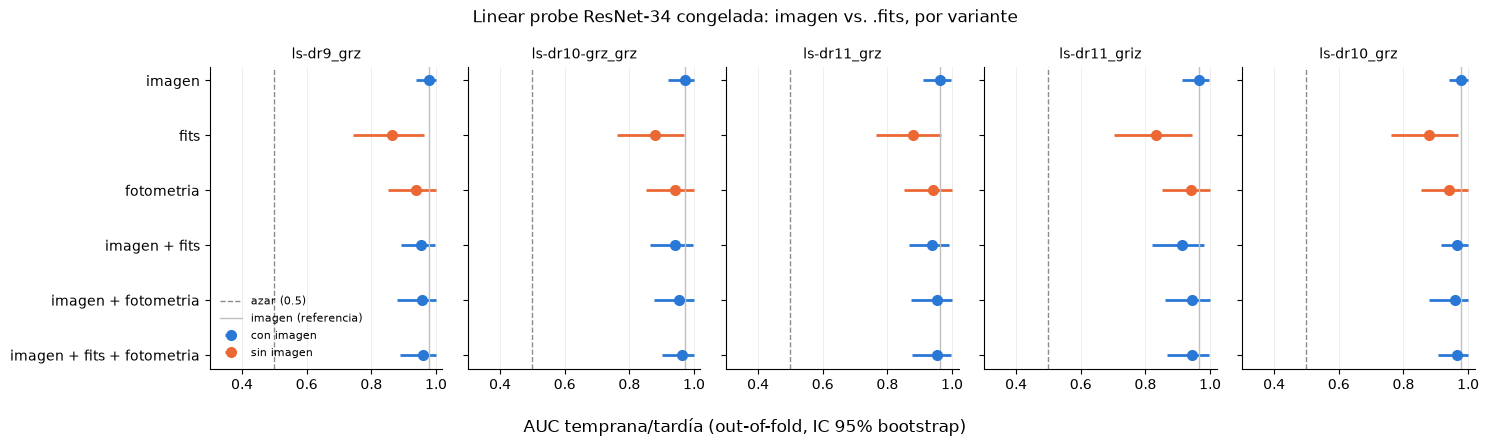

In [6]:
fig, axes = plt.subplots(1, len(variants), figsize=(3.0 * len(variants), 4.4), sharey=True)
ypos = np.arange(len(representations))[::-1]
has_image = np.array(["imagen" in FUSION_REPRESENTATIONS[r] for r in representations])
for ax, variant in zip(axes, variants):
    part = results.loc[variant].loc[representations]
    for group, color in INPUT_COLORS.items():
        sel = has_image == (group == "con imagen")
        ax.errorbar(part["oof_auc"][sel], ypos[sel],
                    xerr=[(part["oof_auc"] - part["oof_ic_inf"])[sel], (part["oof_ic_sup"] - part["oof_auc"])[sel]],
                    fmt="o", markersize=7, color=color, ecolor=color, elinewidth=2, capsize=0, label=group)
    ax.axvline(0.5, color="0.55", linewidth=1, linestyle="--", label="azar (0.5)")
    ax.axvline(part.loc[FUSION_REFERENCE, "oof_auc"], color="0.75", linewidth=1,
               label=f"{FUSION_REFERENCE} (referencia)")
    ax.set_xlim(0.3, 1.02)
    ax.set_title(variant, fontsize=10)
    ax.grid(axis="x", alpha=0.25, linewidth=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_yticks(ypos, representations)
fig.supxlabel("AUC temprana/tardía (out-of-fold, IC 95% bootstrap)")
axes[0].legend(loc="lower left", frameon=False, fontsize=8)
fig.suptitle("Linear probe ResNet-34 congelada: imagen vs. .fits, por variante")
plt.tight_layout()
plt.show()

**Lectura de la figura (para no especialistas).** Un panel por variante. En cada uno, el **punto** es
el AUC de una representación y la **línea** su rango plausible (más corta = más precisa). **Azul** =
usa la imagen; **naranja** = no la usa. La **línea gris vertical** es el AUC de `imagen` sola en esa
variante y la **punteada** el azar.

**Qué se ve:**

1. **Los cinco paneles cuentan la misma historia.** Ningún punto queda a la derecha de la línea gris:
   ninguna combinación supera a la imagen sola en ninguna variante.
2. **`fits` (naranja, segundo renglón) queda siempre lejos y con la línea más larga.** Está más a la
   izquierda en `ls-dr11_griz`.
3. **`fotometria` (naranja, tercer renglón) queda cerca de la imagen en todas.**
4. **`imagen + fits` en `ls-dr11_griz` es el punto azul más a la izquierda (0.91):** la rama del
   `.fits` con la banda *i* incompleta llega a empeorar a la imagen.

**Conclusión:** el resultado de la primera corrida no era una particularidad de `ls-dr10_grz`: se
repite en todas las variantes finalistas.

In [7]:
# Misma tabla en formato compacto: AUC out-of-fold, una columna por variante.
auc_table = results["oof_auc"].unstack("variante").loc[representations, list(variants)]
display(auc_table.round(3))

variante,ls-dr9_grz,ls-dr10-grz_grz,ls-dr11_grz,ls-dr11_griz,ls-dr10_grz
representacion,,,,,
imagen,0.978,0.971,0.963,0.965,0.979
fits,0.864,0.878,0.878,0.834,0.878
fotometria,0.939,0.941,0.941,0.941,0.941
imagen + fits,0.954,0.942,0.939,0.912,0.966
imagen + fotometria,0.955,0.954,0.952,0.944,0.960
imagen + fits + fotometria,0.958,0.963,0.952,0.944,0.966


**Lectura del resultado (para no especialistas).** Es la misma información que la figura, en una
tabla compacta: una columna por variante. Leyendo **hacia abajo** se compara cada representación con
la imagen sola (primera fila), que es la pregunta de esta libreta. Leyendo **a lo ancho** se ve que
cada representación da casi lo mismo en todas las variantes, salvo el `.fits` de `ls-dr11_griz`.

### 2.1 Comparación pareada contra `imagen` sola, dentro de cada variante

Diferencia de AUC de cada representación contra la `imagen` **de la misma variante**
(`FUSION_REFERENCE`) **sobre las mismas galaxias** (bootstrap pareado). Es la prueba que responde la
pregunta de la libreta: si añadir el `.fits` sube el AUC de forma significativa, el intervalo queda
entero por encima de 0.

**Términos de esta sección**

- **Comparación pareada:** en vez de comparar dos promedios, se comparan las dos representaciones
  **galaxia por galaxia**, con las mismas galaxias. Si unas galaxias son fáciles para todas las
  versiones, esa ventaja se cancela y solo queda la diferencia debida a la entrada. Es como comparar
  dos pipelines de fotometría sobre los mismos objetos y no sobre catálogos distintos.
- **`dif_auc`:** AUC de la representación − AUC de `imagen` en la misma variante. Negativo = peor que
  la imagen.
- **`ic_inf` – `ic_sup`:** rango plausible de esa diferencia. **Si incluye el 0, es un empate.**
- **`p_valor`:** **< 0.05 = la diferencia es real.** Un p alto no prueba que sean iguales; dice que con
  50 galaxias no se pueden distinguir.

In [8]:
paired = pd.DataFrame([
    {"variante": variant, "representacion": r,
     **paired_bootstrap_auc_diff(y, oof[(variant, r)], oof[(variant, FUSION_REFERENCE)])}
    for variant in variants for r in representations if r != FUSION_REFERENCE
]).set_index(["variante", "representacion"])
display(paired.round(3))

dif_auc  ic_inf  ic_sup  p_valor
variante        representacion                                              
ls-dr9_grz      fits                         -0.114  -0.216  -0.032    0.002
                fotometria                   -0.038  -0.120   0.018    0.315
                imagen + fits                -0.024  -0.058  -0.000    0.050
                imagen + fotometria          -0.022  -0.093   0.026    0.547
                imagen + fits + fotometria   -0.019  -0.078   0.022    0.514
ls-dr10-grz_grz fits                         -0.093  -0.189  -0.023    0.002
                fotometria                   -0.030  -0.117   0.037    0.502
                imagen + fits                -0.029  -0.068   0.000    0.058
                imagen + fotometria          -0.018  -0.091   0.042    0.678
                imagen + fits + fotometria   -0.008  -0.069   0.045    0.841
ls-dr11_grz     fits                         -0.085  -0.169  -0.019    0.003
                fotometria                   -0.022  -0.107   0.045    0.611
                imagen + fits                -0.024  -0.060   0.002    0.109
                imagen + fotometria          -0.011  -0.083   0.046    0.812
                imagen + fits + fotometria   -0.011  -0.077   0.043    0.771
ls-dr11_griz    fits                         -0.131  -0.242  -0.042    0.002
                fotometria                   -0.024  -0.103   0.035    0.554
                imagen + fits                -0.053  -0.122  -0.002    0.039
                imagen + fotometria          -0.021  -0.093   0.037    0.584
                imagen + fits + fotometria   -0.021  -0.082   0.027    0.494
ls-dr10_grz     fits                         -0.101  -0.201  -0.024    0.002
                fotometria                   -0.038  -0.120   0.021    0.317
                imagen + fits                -0.013  -0.048   0.014    0.525
                imagen + fotometria          -0.019  -0.090   0.032    0.644
                imagen + fits + fotometria   -0.013  -0.062   0.027    0.645

**Lectura del resultado (para no especialistas).** Cada fila compara una representación con la
`imagen` **de la misma variante**, galaxia por galaxia. `dif_auc` negativo = peor que la imagen; si el
rango `ic_inf` – `ic_sup` incluye el 0, es un empate; `p_valor` < 0.05 = diferencia real.

- **`fits` solo es significativamente peor en las cinco variantes** (−0.085 a −0.131, p ≤ 0.003).
- **`imagen + fits`** pierde entre −0.013 y −0.053. Es significativo en `ls-dr11_griz` (p = 0.039),
  justo en el límite en `ls-dr9_grz` (p = 0.050) y empate en las demás.
- **`fotometria`, `imagen + fotometria` e `imagen + fits + fotometria` empatan con la imagen en todas
  las variantes** (p entre 0.32 y 0.84).
- **Ninguna diferencia es positiva:** ninguna representación supera a la imagen en ninguna variante.

In [9]:
# Resumen de la tabla anterior: cuántas combinaciones (variante, representación) son
# significativamente mejores, peores o empatan con la imagen sola.
verdict = np.select([(paired["p_valor"] < 0.05) & (paired["dif_auc"] > 0),
                     (paired["p_valor"] < 0.05) & (paired["dif_auc"] < 0)],
                    ["mejor que imagen", "peor que imagen"], "empate")
display(pd.crosstab(paired.index.get_level_values("representacion"), verdict)
        .reindex(representations[1:]).rename_axis(index="representacion", columns=None))

,empate,peor que imagen
representacion,,
fits,0,5
fotometria,5,0
imagen + fits,4,1
imagen + fotometria,5,0
imagen + fits + fotometria,5,0


**Lectura del resultado (para no especialistas).** Resume la tabla anterior contando, para cada
representación, en cuántas de las 5 variantes es **mejor**, **peor** o **empata** con la imagen sola
(criterio: p < 0.05).

- **"mejor que imagen" no aparece:** 0 de 25 comparaciones.
- **`fits`: peor en 5 de 5.**
- **`imagen + fits`: peor en 1 (`ls-dr11_griz`), empate en 4.**
- **Todo lo demás: empate en 5 de 5.**

**Conclusión:** la respuesta a la pregunta de la libreta es la misma en las cinco variantes.

### 2.2 Aciertos y errores

Para cada variante, los errores de `imagen` sola y de la combinación completa
`imagen + fits + fotometria` (predicciones out-of-fold, umbral 0.5), separados por tipo: tempranas
llamadas tardías y tardías llamadas tempranas. Abajo, las galaxias que la imagen sola clasifica mal en
alguna variante: si fallan en todas, el problema probablemente está en la galaxia (caso frontera), no en
la variante.

**Términos de esta sección**

- **Matriz de confusión:** tabla 2×2 que cruza la clase real con la predicha. La diagonal son los
  aciertos; las otras dos casillas son los dos tipos de error (tempranas llamadas tardías, y al revés).
  Aquí se resume en dos columnas: `temprana→tardia` y `tardia→temprana`.
- **`p_tardia`:** probabilidad de "tardía" que le dio el modelo a la galaxia. Arriba de 0.5 se
  clasifica como tardía.

In [10]:
FULL = "imagen + fits + fotometria"
class_names = sorted(MORFOLOGIA_LABEL_TO_INT, key=MORFOLOGIA_LABEL_TO_INT.get)
error_rows = []
for variant in variants:
    for representation in (FUSION_REFERENCE, FULL):
        cm = confusion_matrix(y, (oof[(variant, representation)] >= 0.5).astype(int))
        error_rows.append({"variante": variant, "representacion": representation,
                           "aciertos": int(np.trace(cm)),
                           f"{class_names[0]}→{class_names[1]}": int(cm[0, 1]),
                           f"{class_names[1]}→{class_names[0]}": int(cm[1, 0])})
display(pd.DataFrame(error_rows).set_index(["variante", "representacion"]))

wrong_image = pd.DataFrame({variant: (oof[(variant, FUSION_REFERENCE)] >= 0.5) != y for variant in variants},
                           index=names)
wrong_full = pd.DataFrame({variant: (oof[(variant, FULL)] >= 0.5) != y for variant in variants}, index=names)
hard = galaxies.set_index("name")[["label"]].assign(
    variantes_con_error_imagen=wrong_image.sum(axis=1),
    variantes_con_error_combinada=wrong_full.sum(axis=1),
    p_tardia_imagen_media=np.mean([oof[(v, FUSION_REFERENCE)] for v in variants], axis=0),
)
hard = hard[(hard["variantes_con_error_imagen"] > 0) | (hard["variantes_con_error_combinada"] > 0)]
print(f"Galaxias con algún error de {FUSION_REFERENCE} o de {FULL} en alguna de las {len(variants)} variantes: {len(hard)}")
display(hard.sort_values(["variantes_con_error_imagen", "variantes_con_error_combinada"], ascending=False).round(3))

aciertos  temprana→tardia  \
variante        representacion                                          
ls-dr9_grz      imagen                            46                1   
                imagen + fits + fotometria        45                2   
ls-dr10-grz_grz imagen                            46                1   
                imagen + fits + fotometria        45                2   
ls-dr11_grz     imagen                            44                1   
                imagen + fits + fotometria        45                2   
ls-dr11_griz    imagen                            44                1   
                imagen + fits + fotometria        45                2   
ls-dr10_grz     imagen                            46                0   
                imagen + fits + fotometria        46                2   

                                            tardia→temprana  
variante        representacion                               
ls-dr9_grz      imagen                                    3  
                imagen + fits + fotometria                3  
ls-dr10-grz_grz imagen                                    3  
                imagen + fits + fotometria                3  
ls-dr11_grz     imagen                                    5  
                imagen + fits + fotometria                3  
ls-dr11_griz    imagen                                    5  
                imagen + fits + fotometria                3  
ls-dr10_grz     imagen                                    4  
                imagen + fits + fotometria                2

Galaxias con algún error de imagen o de imagen + fits + fotometria en alguna de las 5 variantes: 8


,label,variantes_con_error_imagen,variantes_con_error_combinada,p_tardia_imagen_media
name,,,,
manga-9037-6102,tardia,5,5,0.323
manga-12495-1901,tardia,5,4,0.211
manga-9863-6102,temprana,4,5,0.574
manga-8728-9101,tardia,4,0,0.418
manga-8728-6104,tardia,3,0,0.436
manga-11979-6101,tardia,2,5,0.579
manga-12075-3704,tardia,1,0,0.584
manga-8481-6104,temprana,0,5,0.339


**Lectura del resultado (para no especialistas).**

**Tabla de errores.** Para cada variante, aciertos de la imagen sola y de la combinación completa, y
los dos tipos de error:

- **La imagen sola** acierta 46 de 50 en DR9, DR10 y DR10-grz y 44 en las dos DR11. **Casi todos sus
  errores son tardías llamadas tempranas** (3 a 5 por variante, contra 0 o 1 en el otro sentido), el
  mismo patrón de la libreta de solo imágenes.
- **La combinación completa** acierta 45–46 en todas. Reparte mejor los errores (2 tempranas y 2–3
  tardías), pero no comete menos en total. En DR11 gana una galaxia (44 → 45), y en DR9 y DR10-grz
  pierde una (46 → 45).

**Tabla de galaxias.** Las 8 galaxias que alguna de las dos versiones clasifica mal en alguna
variante. Las columnas `variantes_con_error_*` dicen en cuántas de las 5 variantes falla cada versión.

- **Difíciles para todo:** `manga-9037-6102` y `manga-12495-1901` (tardías) fallan con la imagen en
  las 5 variantes y casi siempre también con la combinación. `manga-9863-6102` (temprana) falla en 4
  y 5. Si fallan en todas las variantes y con todas las entradas, lo más probable es que sean **casos
  frontera** y no un problema de la imagen.
- **Las corrige el color y la concentración:** `manga-8728-9101`, `manga-8728-6104` y
  `manga-12075-3704` (tardías). La imagen las confunde en 1 a 4 variantes y la combinación no falla en
  ninguna.
- **Las estropea la combinación:** `manga-11979-6101` (tardía) y `manga-8481-6104` (temprana) fallan
  con la combinación en las 5 variantes, y la imagen solo falla con la primera en 2 variantes.

### Conclusión de la sección 2

- **En las cinco variantes, la imagen sola es la mejor opción:** AUC 0.963–0.979 y 44–46 aciertos.
- **Añadir el `.fits`, la fotometría o ambos no mejora** en ninguna: 0 de 25 comparaciones a favor.
  Los errores cambian de galaxia, pero su número no baja.
- **El `.fits` solo es claramente peor en todas** (p ≤ 0.003). Con `ls-dr11_griz`, sumarlo a la
  imagen llega a empeorarla (p = 0.039).
- **Tres números de fotometría casi igualan a la imagen** en todas las variantes (AUC 0.94, empate).
- **Hay galaxias difíciles para cualquier variante y entrada**, lo que apunta a la galaxia y no al
  formato.

**Interpretación:** la imagen del visor ya contiene lo que aportan el `.fits` y la fotometría (forma,
estructura y color), así que juntarlos no suma información nueva, y esto no depende de la variante.
El `.fits` solo rinde peor por cómo se usó, no porque contenga menos información. La red se entrenó
con fotos cotidianas, y el `.fits` normalizado es una imagen con otra estadística a la que una red
congelada no se puede adaptar. Con `griz`, además, la banda *i* vacía en el norte añade un defecto
propio.

## 3. Rendimiento por región y generalización norte ↔ sur

El `.fits` conserva el color calibrado, y la diferencia de filtros entre norte (BASS/MzLS) y sur
(DECam) sigue en el dato: r − z es ~0.1–0.15 mayor en el sur (`README.md`, sección "Normalización de
los .fits"). Es un riesgo nuevo que el `.jpg` no tenía en la misma forma. Mismas pruebas que la sección
3 de la libreta de solo imágenes:

- **AUC por región** de las predicciones out-of-fold;
- **entrenar en una región y evaluar en la otra**.

**Términos de esta sección**

- **`auc_oof_norte` / `auc_oof_sur`:** el AUC calculado por separado con las galaxias de cada región.
  El modelo aprendió con ambas.
- **`auc_norte→sur`:** el modelo aprende **solo con galaxias del norte** y se califica con las del sur,
  que nunca vio (y `auc_sur→norte` al revés). Es la prueba más exigente: si el modelo dependiera del
  telescopio, aquí se desplomaría.
- **Generalizar:** que lo aprendido con unos datos funcione con datos distintos, en este caso de otro
  telescopio.

In [11]:
region_rows = []
for variant in variants:
    for representation in representations:
        X, sizes = representation_matrix(variant, representation)
        row = {"variante": variant, "representacion": representation}
        for region in (LEGACY_REGION_NORTH, LEGACY_REGION_SOUTH):
            sel = regions == region
            row[f"auc_oof_{region}"] = bootstrap_auc_ci(y[sel], oof[(variant, representation)][sel])["auc"]
        for cross in cross_group_auc(make_fusion_probe(sizes), X, y, regions):
            row[f"auc_{cross['entrena']}→{cross['evalua']}"] = cross["auc"]
        region_rows.append(row)

by_region = pd.DataFrame(region_rows).set_index(["variante", "representacion"])
display(by_region.round(3))

auc_oof_norte  auc_oof_sur  \
variante        representacion                                           
ls-dr9_grz      imagen                              1.000        0.962   
                fits                                0.985        0.758   
                fotometria                          0.924        0.962   
                imagen + fits                       1.000        0.918   
                imagen + fotometria                 0.924        0.984   
                imagen + fits + fotometria          0.947        0.978   
ls-dr10-grz_grz imagen                              0.992        0.951   
                fits                                0.985        0.786   
                fotometria                          0.924        0.962   
                imagen + fits                       1.000        0.879   
                imagen + fotometria                 0.924        0.984   
                imagen + fits + fotometria          0.939        0.984   
ls-dr11_grz     imagen                              0.985        0.940   
                fits                                0.985        0.780   
                fotometria                          0.924        0.962   
                imagen + fits                       0.985        0.885   
                imagen + fotometria                 0.924        0.978   
                imagen + fits + fotometria          0.939        0.973   
ls-dr11_griz    imagen                              0.977        0.951   
                fits                                0.917        0.753   
                fotometria                          0.924        0.962   
                imagen + fits                       0.970        0.852   
                imagen + fotometria                 0.902        0.978   
                imagen + fits + fotometria          0.932        0.962   
ls-dr10_grz     imagen                              0.992        0.956   
                fits                                0.985        0.786   
                fotometria                          0.924        0.962   
                imagen + fits                       1.000        0.912   
                imagen + fotometria                 0.932        0.989   
                imagen + fits + fotometria          0.947        0.984   

                                            auc_norte→sur  auc_sur→norte  
variante        representacion                                            
ls-dr9_grz      imagen                              0.978          1.000  
                fits                                0.808          0.947  
                fotometria                          0.940          0.924  
                imagen + fits                       0.907          0.992  
                imagen + fotometria                 0.978          0.924  
                imagen + fits + fotometria          0.973          0.939  
ls-dr10-grz_grz imagen                              0.984          0.970  
                fits                                0.808          0.947  
                fotometria                          0.945          0.924  
                imagen + fits                       0.901          0.955  
                imagen + fotometria                 0.984          0.917  
                imagen + fits + fotometria          0.978          0.939  
ls-dr11_grz     imagen                              0.967          0.955  
                fits                                0.802          0.939  
                fotometria                          0.940          0.924  
                imagen + fits                       0.879          0.955  
                imagen + fotometria                 0.984          0.917  
                imagen + fits + fotometria          0.967          0.924  
ls-dr11_griz    imagen                              0.962          0.939  
                fits                                0.791          0.886  
                fotometri

**Lectura del resultado (para no especialistas).** AUC dentro de cada región y AUC al aprender en una
región y calificar en la otra, para cada variante y representación. Hay 23 galaxias en el norte y 27
en el sur.

- **`imagen`:** funciona bien en ambas regiones en todas las variantes: 0.98–1.00 en el norte y
  0.94–0.96 en el sur. Al cruzar de región da 0.96–1.00 y 0.94–1.00.
- **`fits` solo cae en el sur en todas las variantes:** 0.75–0.79 dentro del sur y 0.79–0.81 al
  aprender en el norte y calificar en el sur. El `.fits` conserva la diferencia real de filtros entre
  los dos telescopios (r − z ~0.1–0.15 mayor en el sur), y la red no sabe que es la misma galaxia
  "vista con otro filtro".
- **`imagen + fits`** también baja en el sur (0.85–0.92) y al cruzar del norte al sur (0.85–0.93).
  El peor caso es `ls-dr11_griz`.
- **Las representaciones con fotometría** rinden algo mejor en el sur que en el norte (0.96–0.99 vs.
  0.90–0.95).

**Cautela:** con ~25 galaxias por región, una o dos galaxias mueven el AUC varias centésimas. Solo la
caída del `.fits` en el sur es grande y se repite en todas las variantes.

### 3.1 ¿La representación delata la región?

Misma prueba de predictibilidad, pero ahora prediciendo **norte/sur** en vez de temprana/tardía. Un AUC
alto no es un problema por sí mismo (la región no está asociada a la clase en esta muestra), pero
indica que el modelo *podría* usar el telescopio como atajo si en otra muestra la región y la clase
estuvieran correlacionadas.

**Términos de esta sección**

- **Atajo (*shortcut*):** una pista que permite acertar en el examen sin saber la materia. Ejemplo: si
  en una muestra casi todas las espirales vinieran del sur y el `.jpg` del sur es morado, el modelo
  podría aprender "morado → espiral" en vez de reconocer brazos y discos, y fallaría en cuanto esa
  coincidencia desapareciera.
- **AUC de región:** misma calificación que antes, pero para adivinar norte/sur en lugar de la clase.
  0.5 = la entrada no revela el telescopio; 1.0 = lo revela sin error.

In [12]:
is_south = (regions == LEGACY_REGION_SOUTH).astype(int)
leak_rows = []
for variant in variants:
    for representation in representations:
        X, sizes = representation_matrix(variant, representation)
        leak_rows.append({"variante": variant, "representacion": representation,
                          **predictability_test(make_fusion_probe(sizes), X, is_south)})
region_leak = pd.DataFrame(leak_rows).set_index(["variante", "representacion"])
display(region_leak["auc_media"].unstack("variante").loc[representations, list(variants)].round(3))

variante,ls-dr9_grz,ls-dr10-grz_grz,ls-dr11_grz,ls-dr11_griz,ls-dr10_grz
representacion,,,,,
imagen,0.809,0.830,0.810,0.839,1.000
fits,0.772,0.789,0.781,0.972,0.789
fotometria,0.822,0.822,0.867,0.867,0.822
imagen + fits,0.812,0.843,0.823,0.982,1.000
imagen + fotometria,0.948,0.960,0.971,0.977,1.000
imagen + fits + fotometria,0.932,0.947,0.956,0.993,1.000


**Lectura del resultado (para no especialistas).** Aquí no se adivina la clase, sino **en qué región
del cielo (telescopio) se observó la galaxia**, solo con lo que recibe el modelo. Una columna por
variante.

- **`imagen`:** 0.81–0.84 en las cuatro finalistas, contra **1.00 en `ls-dr10_grz`**. El morado del
  visor delata el telescopio sin error, y las finalistas lo delatan mucho menos. Confirma con otra
  prueba el filtro 1 de la libreta de solo imágenes.
- **`fits` grz: 0.77–0.79**, por la diferencia física de filtros.
- **`fits` de `ls-dr11_griz`: 0.97.** La banda *i* vacía en el norte delata casi perfectamente el
  telescopio, y explica por qué esta variante es la peor con `.fits`.
- **`fotometria`: 0.82–0.87.**
- **`imagen + fotometria`: 0.95–0.98 en las finalistas.** Juntas delatan la región más que cada una por separado. Cada
  una lleva una pista débil del telescopio y la fórmula las suma.

**Conclusión:** en esta muestra la región no está asociada a la clase, así que estas pistas no
inflan los resultados. Pero ninguna representación está libre de "pistas de telescopio". Las
finalistas reducen la del `.jpg`, y añadir `.fits` o fotometría la vuelve a subir.

### Conclusión de la sección 3

- **La imagen de cualquier variante generaliza entre telescopios:** lo aprendido con el norte funciona
  con el sur y al revés (AUC 0.94–1.00).
- **El `.fits` solo no generaliza al sur en ninguna variante** (0.75–0.79 dentro del sur).
- **Con las finalistas, el `.jpg` es la entrada que menos revela el telescopio** (0.81–0.84). El
  `.fits` grz revela algo parecido (~0.78), `ls-dr11_griz` casi todo (0.97) y las combinaciones con
  fotometría bastante (0.93–0.99).

**Interpretación:** pasar a una variante finalista quita la pista más fuerte del `.jpg` (el morado),
y añadir el `.fits` o la fotometría reintroduce pistas de telescopio sin mejorar la clasificación. Si
en el futuro se usa el `.fits`, convendría corregir antes la diferencia de filtros BASS/MzLS vs. DECam
y **no usar la banda *i* de DR11**, que no existe en el norte.

## 4. Control: normalización del `.fits` medida dentro de cada fold

La escala global y la estandarización por banda del `.fits` se midieron arriba con las 50 galaxias (sin
etiquetas). `README.md` pide medirlas **solo con el set de entrenamiento**; aquí se repite el AUC
out-of-fold así, fold por fold (`fits_out_of_fold_proba_foldwise`), en cada variante. Si la diferencia
es ~0, los resultados de las secciones 2 y 3 son válidos.

**Términos de esta sección**

- **Fuga de información (*data leakage*):** que el modelo, sin querer, tenga acceso a algo de las
  galaxias con las que se le va a calificar; como ver el examen antes de presentarlo. Infla los
  resultados.
- **Aquí, el riesgo:** para normalizar el `.fits` se miden constantes con la muestra (brillo de
  referencia, ruido típico, promedio de cada banda). Si se miden con todas las galaxias, incluidas las
  de calificación, hay una fuga pequeña. No usan las etiquetas, pero lo estricto es medirlas solo con
  las galaxias de aprendizaje de cada ronda. Esta sección compara las dos formas.

In [13]:
foldwise_rows = []
for variant, (layer, bands) in variants.items():
    for representation in representations:
        parts = FUSION_REPRESENTATIONS[representation]
        if "fits" not in parts:
            continue
        others = [blocks[variant][block] for block in parts if block != "fits"]
        proba = fits_out_of_fold_proba_foldwise(raws[variant], y, backbone, bands, other_blocks=others)
        foldwise_rows.append({"variante": variant, "representacion": representation,
                              "auc_normalizacion_global": results.loc[(variant, representation), "oof_auc"],
                              "auc_normalizacion_por_fold": bootstrap_auc_ci(y, proba)["auc"]})

foldwise = pd.DataFrame(foldwise_rows).set_index(["variante", "representacion"])
foldwise["diferencia"] = foldwise["auc_normalizacion_por_fold"] - foldwise["auc_normalizacion_global"]
display(foldwise.round(3))

auc_normalizacion_global  \
variante        representacion                                         
ls-dr9_grz      fits                                           0.864   
                imagen + fits                                  0.954   
                imagen + fits + fotometria                     0.958   
ls-dr10-grz_grz fits                                           0.878   
                imagen + fits                                  0.942   
                imagen + fits + fotometria                     0.963   
ls-dr11_grz     fits                                           0.878   
                imagen + fits                                  0.939   
                imagen + fits + fotometria                     0.952   
ls-dr11_griz    fits                                           0.834   
                imagen + fits                                  0.912   
                imagen + fits + fotometria                     0.944   
ls-dr10_grz     fits                                           0.878   
                imagen + fits                                  0.966   
                imagen + fits + fotometria                     0.966   

                                            auc_normalizacion_por_fold  \
variante        representacion                                           
ls-dr9_grz      fits                                             0.867   
                imagen + fits                                    0.954   
                imagen + fits + fotometria                       0.958   
ls-dr10-grz_grz fits                                             0.875   
                imagen + fits                                    0.942   
                imagen + fits + fotometria                       0.963   
ls-dr11_grz     fits                                             0.877   
                imagen + fits                                    0.936   
                imagen + fits + fotometria                       0.952   
ls-dr11_griz    fits                                             0.837   
                imagen + fits                                    0.914   
                imagen + fits + fotometria                       0.946   
ls-dr10_grz     fits                                             0.875   
                imagen + fits                                    0.965   
                imagen + fits + fotometria                       0.966   

                                            diferencia  
variante        representacion                          
ls-dr9_grz      fits                             0.003  
                imagen + fits                    0.000  
                imagen + fits + fotometria       0.000  
ls-dr10-grz_grz fits                            -0.003  
                imagen + fits                    0.000  
                imagen + fits + fotometria       0.000  
ls-dr11_grz     fits                            -0.002  
                imagen + fits                   -0.003  
                imagen + fits + fotometria       0.000  
ls-dr11_griz    fits                             0.003  
                imagen + fits                    0.002  
                imagen + fits + fotometria       0.002  
ls-dr10_grz     fits                            -0.003  
                imagen + fits                   -0.002  
                imagen + fits + fotometria       0.000

**Lectura del resultado (para no especialistas).** Es una prueba de honestidad del procedimiento. Para
normalizar el `.fits` hay que medir unas constantes (brillo de referencia, nivel de ruido); lo estricto
es medirlas solo con las galaxias de entrenamiento de cada ronda. Aquí se repite así en cada variante
y se compara.

**Qué dicen los números:** las diferencias van de −0.003 a +0.003 de AUC en todas las variantes,
prácticamente cero.

### Conclusión de la sección 4

- Medir la normalización solo con las galaxias de aprendizaje cambia el AUC en 0.003 o menos, en las
  cinco variantes.

**Interpretación:** el procedimiento rápido no infló los resultados, así que las conclusiones de las
secciones 2 y 3 son confiables en este aspecto. Con el dataset completo se recomienda usar siempre la
versión estricta.

## 5. Resumen

Una fila por (variante, representación), ordenada por variante y AUC. Cómo leerla:

1. La pregunta es si alguna representación con `.fits` **supera a `imagen` de su misma variante** de
   forma significativa (`dif_vs_imagen` > 0 con `p_vs_imagen` < 0.05).
2. Si empatan, preferir la más simple: `imagen` sola (un archivo de pocos KB por galaxia, sin
   normalización propia) frente a `.fits` (~770 KB y un pipeline de normalización).
3. Revisar que no se desplome **entre regiones** (`auc_norte→sur`, `auc_sur→norte`) y cuánto delata la
   región (`auc_region`).

In [14]:
summary = results[["oof_auc", "oof_ic_inf", "oof_ic_sup", "f1_macro", "accuracy"]].copy()
summary[f"dif_vs_{FUSION_REFERENCE}"] = paired["dif_auc"]
summary[f"p_vs_{FUSION_REFERENCE}"] = paired["p_valor"]
summary["auc_norte→sur"] = by_region[f"auc_{LEGACY_REGION_NORTH}→{LEGACY_REGION_SOUTH}"]
summary["auc_sur→norte"] = by_region[f"auc_{LEGACY_REGION_SOUTH}→{LEGACY_REGION_NORTH}"]
summary["auc_region"] = region_leak["auc_media"]
order = summary.reset_index().assign(v=lambda d: d["variante"].map(list(variants).index))
order = order.sort_values(["v", "oof_auc"], ascending=[True, False]).set_index(["variante", "representacion"]).index
display(summary.loc[order].round(3))

oof_auc  oof_ic_inf  oof_ic_sup  \
variante        representacion                                                
ls-dr9_grz      imagen                        0.978       0.937       1.000   
                imagen + fits + fotometria    0.958       0.890       1.000   
                imagen + fotometria           0.955       0.878       1.000   
                imagen + fits                 0.954       0.893       0.997   
                fotometria                    0.939       0.852       1.000   
                fits                          0.864       0.745       0.962   
ls-dr10-grz_grz imagen                        0.971       0.918       1.000   
                imagen + fits + fotometria    0.963       0.902       1.000   
                imagen + fotometria           0.954       0.877       1.000   
                imagen + fits                 0.942       0.864       0.997   
                fotometria                    0.941       0.853       1.000   
                fits                          0.878       0.763       0.968   
ls-dr11_grz     imagen                        0.963       0.909       0.997   
                imagen + fotometria           0.952       0.873       1.000   
                imagen + fits + fotometria    0.952       0.877       0.997   
                fotometria                    0.941       0.853       1.000   
                imagen + fits                 0.939       0.866       0.992   
                fits                          0.878       0.765       0.967   
ls-dr11_griz    imagen                        0.965       0.913       0.997   
                imagen + fotometria           0.944       0.860       1.000   
                imagen + fits + fotometria    0.944       0.866       0.995   
                fotometria                    0.941       0.853       1.000   
                imagen + fits                 0.912       0.820       0.982   
                fits                          0.834       0.702       0.943   
ls-dr10_grz     imagen                        0.979       0.942       1.000   
                imagen + fits + fotometria    0.966       0.907       1.000   
                imagen + fits                 0.966       0.915       1.000   
                imagen + fotometria           0.960       0.880       1.000   
                fotometria                    0.941       0.853       1.000   
                fits                          0.878       0.763       0.968   

                                            f1_macro  accuracy  dif_vs_imagen  \
variante        representacion                                                  
ls-dr9_grz      imagen                         0.920      0.92            NaN   
                imagen + fits + fotometria     0.900      0.90         -0.019   
                imagen + fotometria            0.920      0.92         -0.022   
                imagen + fits                  0.879      0.88         -0.024   
                fotometria                     0.860      0.86         -0.038   
                fits                           0.859      0.86         -0.114   
ls-dr10-grz_grz imagen                         0.920      0.92            NaN   
                imagen + fits + fotometria     0.900      0.90         -0.008   
                imagen + fotometria            0.900      0.90         -0.018   
                imagen + fits                  0.879      0.88         -0.029   
                fotometria                     0.860      0.86         -0.030   
                fits                           0.859      0.86         -0.093   
ls-dr11_grz     imagen                         0.879      0.88            NaN   
                imagen + fotometria            0.920      0.92         -0.011   
                imagen + fits + fotometria     0.900      0.90         -0.011   
                fotometria                     0.860      0.86         -0.022   
                imagen + fits                  0.879     

**Lectura del resultado (para no especialistas).** Tabla final: dentro de cada variante, las
representaciones ordenadas de mayor a menor AUC. Junta todo lo anterior: AUC y su rango, aciertos,
diferencia contra la imagen sola, generalización entre regiones y cuánto delata la región
(`auc_region`).

**Qué se ve:** en las cinco variantes, `imagen` sola encabeza su bloque y `fits` solo queda último.
Ninguna combinación tiene `dif_vs_imagen` positivo. Entre las finalistas, las filas que menos delatan
la región son `imagen`, `fits` e `imagen + fits` con bandas grz (`auc_region` 0.77–0.84).

**Conclusión:** con esta muestra, **la imagen sola es suficiente en cualquiera de las variantes
finalistas**. Ver las conclusiones generales abajo.

## Observaciones y conclusiones (muestra de 50, 2026-10-19)

**Pregunta:** ¿es mejor usar solo imágenes o imágenes + `.fits`, y depende de la variante?
**Respuesta con esta muestra: solo imágenes, en todas las variantes.**

1. **El `.fits` no mejora a la imagen en ninguna variante.** En las 25 comparaciones (5 variantes × 5
   representaciones con `.fits` o fotometría) ninguna supera a la imagen sola. 19 empatan, y 6 son
   significativamente peores: `fits` solo en las 5 variantes e `imagen + fits` en `ls-dr11_griz`
   (p = 0.039).

2. **El resultado de la primera corrida se generaliza.** `ls-dr10_grz` (la variante de la primera
   corrida) y las cuatro finalistas dan el mismo cuadro. La conclusión no era un efecto del morado del
   visor.

3. **El `.fits` solo es peor en todas las variantes** (AUC 0.83–0.88, p ≤ 0.003), sobre todo en el sur
   (0.75–0.79). Dos causas probables:
   - la red se entrenó con fotos cotidianas, y el `.fits` normalizado es una imagen con otro
     estiramiento y otro balance de color que el render del visor;
   - el `.fits` conserva la diferencia de filtros entre telescopios.

   Con la red congelada no puede adaptarse a ninguna de las dos.

4. **`ls-dr11_griz` tiene un problema propio en el `.fits`:** la banda *i* está vacía en el norte (y
   en 2 galaxias del sur), así que el `.fits` delata el telescopio casi sin error (AUC de región 0.97)
   y es el peor de todos (0.834). Su `.jpg` no muestra este problema: pasó el control de color de la
   libreta de solo imágenes y su `auc_region` es 0.84, como el de las otras finalistas.

5. **La fotometría clásica es sorprendentemente buena:** g − r, r − z y concentración dan AUC 0.94 en
   todas las variantes, en empate con la imagen. Es una validación física del problema: color y
   concentración son los indicadores de tipo morfológico conocidos en la literatura.

6. **Costo contra beneficio.** El `.fits` pesa ~770 KB por galaxia (~1 MB con griz), contra pocos KB
   del `.jpg`. Además necesita su propio pipeline de normalización y no da ganancia medible en ninguna
   variante. **Recomendación: entrenar con el `.jpg` de una variante finalista** y mantener el `.fits`
   para medir, como ya establece `README.md` (sección "Formato de las imágenes").

**Qué no descarta este resultado:**

- **Fine-tuning.** Con la red congelada, el `.fits` está en desventaja, porque la red espera fotos
  cotidianas. Reentrenando la red con ~2,000 galaxias el `.fits` podría rendir distinto; se puede
  repetir esta comparación entonces.
- **La muestra.** Con 50 galaxias solo se detectan diferencias grandes; una mejora de ~0.01 de AUC no
  se vería.
- **La elección entre finalistas.** Esta libreta no la resuelve: con `.fits` o sin él, DR9 y DR11
  siguen empatados.

**Preguntas para el equipo de astronomía:**

- `manga-9037-6102` y `manga-12495-1901` (tardías) se clasifican como tempranas en todas las
  variantes y con todas las entradas, y `manga-9863-6102` (temprana) como tardía. ¿Son casos frontera
  (S0/Sa, espirales rojas o con bulbo dominante) o conviene revisar su `Ttype`?
- `manga-8728-9101`, `manga-8728-6104` y `manga-12075-3704` (tardías) las confunde la imagen y las
  corrigen el color y la concentración. ¿Son espirales rojas o de brazos débiles?
- ¿Hay una corrección estándar de la diferencia de filtros BASS/MzLS vs. DECam que convenga aplicar
  al `.fits` antes de usarlo como entrada?
- ¿Se espera que la banda *i* de DR11 falte en todo el norte, o es algo de estos cutouts?